# **DeepForest 🌳**

# Imports | Installes | Initializations

In [ ]:
!pip install rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 15.5 MB/s eta 0:00:00


In [ ]:
import requests
import geemap
from PIL import Image # Import Image from PIL
from io import BytesIO
import matplotlib.pyplot as plt
import numpy as np
from osgeo import gdal
from google.colab import drive
from rasterio.plot import show
import rasterio
import math
import json
import pandas as pd

In [ ]:
# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Initialize the Study Areas defined in EPSG:3857
# |   0 = Schwarzwald   |   1 = Bayerischer Wald   |   2 = Ebersberg   |   3 = oberösterreichische Kalkalpen   |   4 = Wien   |   5 = Würzburg   |
bounding_box = [[931000,6208000, 972100,6232800],[1443000,6300000, 1484000,6319000],[1310400,6112900, 1358500,6143100], [1581700,6082700, 1624400,6103600], [1771000,6104700, 1816100,6128000], [1029700,6421200, 1072400,6444500]] # 0 is Schwarzwald, 1 is Bayerischer Wald, 2 is Ebersberg groß, 3 is oberösterreichische Kalkalpen, 4 is Wien, 5 is Würzburg

# Target Data

##Fetch Target Image

ROI 0: Width: 4110 pixels, Height: 2480 pixels
GeoTIFF saved to: /content/drive/MyDrive/Forest_AI_Data/leaf_type_data_10m_0.tif
CRS: EPSG:3857
Transform: | 10.00, 0.00, 931000.00|
| 0.00,-10.00, 6232800.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=931000.0, bottom=6208000.0, right=972100.0, top=6232800.0)
Resolution X: 10.0 meters
Resolution Y: 10.0 meters
Shape: (2480, 4110)


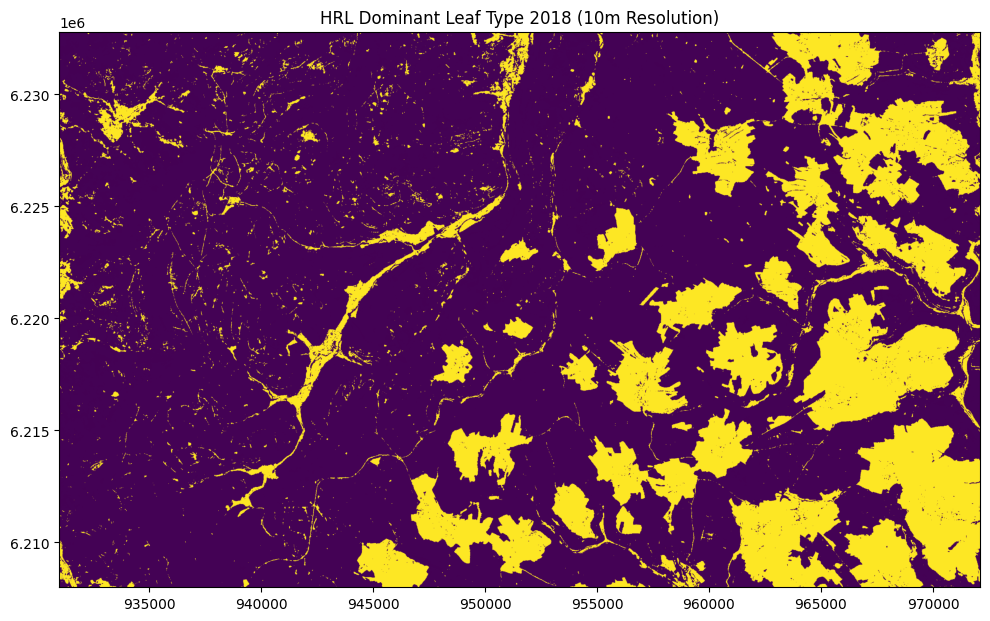

ROI 1: Width: 4100 pixels, Height: 1900 pixels
GeoTIFF saved to: /content/drive/MyDrive/Forest_AI_Data/leaf_type_data_10m_1.tif
CRS: EPSG:3857
Transform: | 10.00, 0.00, 1443000.00|
| 0.00,-10.00, 6319000.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=1443000.0, bottom=6300000.0, right=1484000.0, top=6319000.0)
Resolution X: 10.0 meters
Resolution Y: 10.0 meters
Shape: (1900, 4100)


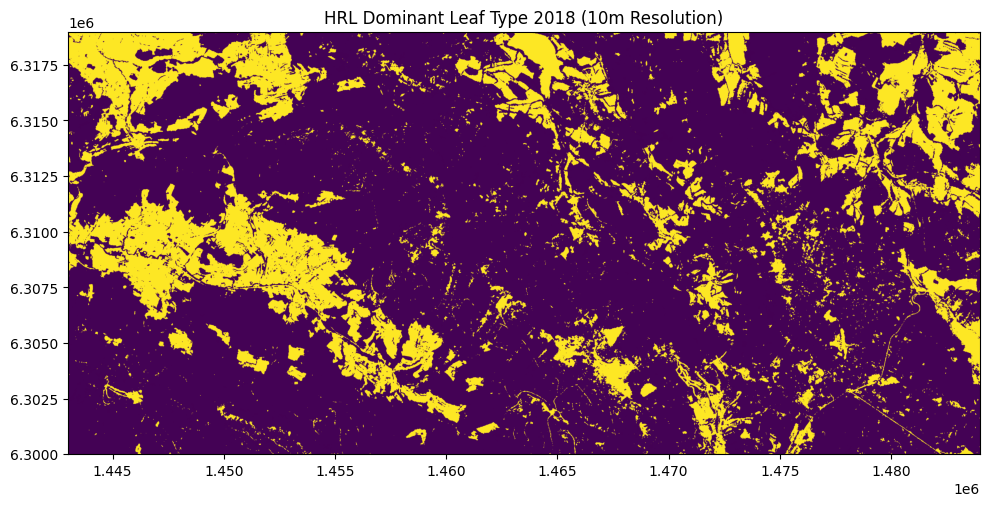

ROI 2: Width: 4810 pixels, Height: 3020 pixels
GeoTIFF saved to: /content/drive/MyDrive/Forest_AI_Data/leaf_type_data_10m_2.tif
CRS: EPSG:3857
Transform: | 10.00, 0.00, 1310400.00|
| 0.00,-10.00, 6143100.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=1310400.0, bottom=6112900.0, right=1358500.0, top=6143100.0)
Resolution X: 10.0 meters
Resolution Y: 10.0 meters
Shape: (3020, 4810)


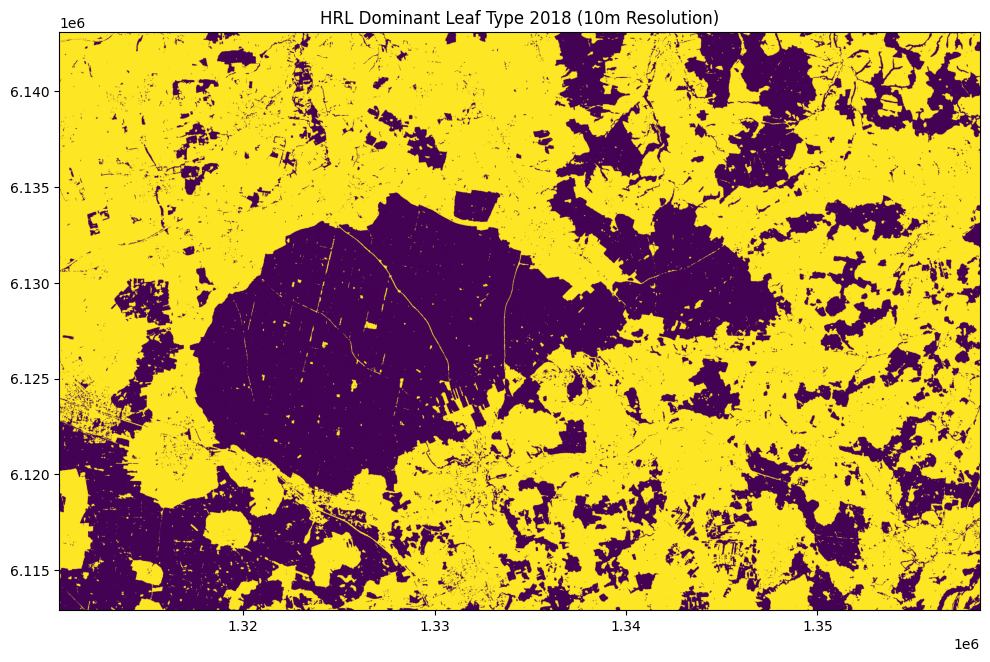

ROI 3: Width: 4270 pixels, Height: 2090 pixels
GeoTIFF saved to: /content/drive/MyDrive/Forest_AI_Data/leaf_type_data_10m_3.tif
CRS: EPSG:3857
Transform: | 10.00, 0.00, 1581700.00|
| 0.00,-10.00, 6103600.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=1581700.0, bottom=6082700.0, right=1624400.0, top=6103600.0)
Resolution X: 10.0 meters
Resolution Y: 10.0 meters
Shape: (2090, 4270)


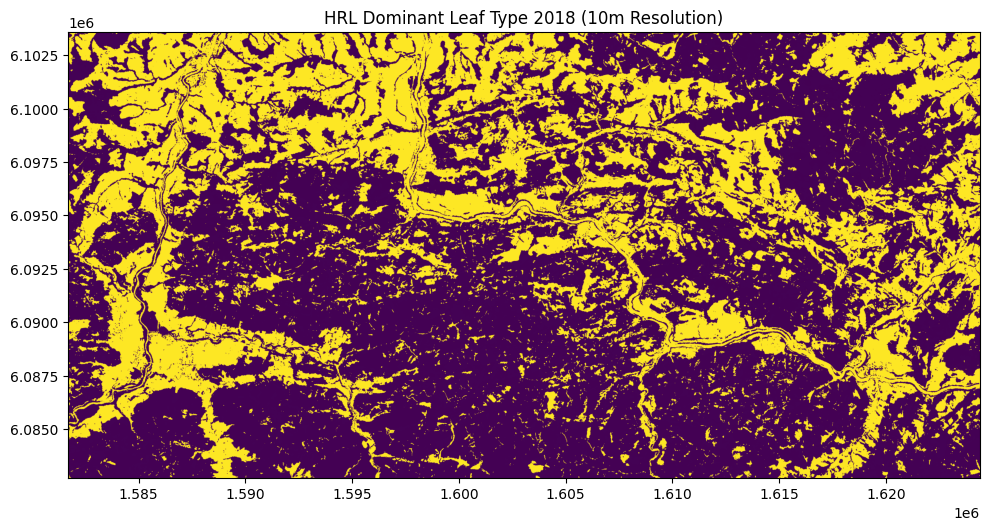

ROI 4: Width: 4510 pixels, Height: 2330 pixels
GeoTIFF saved to: /content/drive/MyDrive/Forest_AI_Data/leaf_type_data_10m_4.tif
CRS: EPSG:3857
Transform: | 10.00, 0.00, 1771000.00|
| 0.00,-10.00, 6128000.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=1771000.0, bottom=6104700.0, right=1816100.0, top=6128000.0)
Resolution X: 10.0 meters
Resolution Y: 10.0 meters
Shape: (2330, 4510)


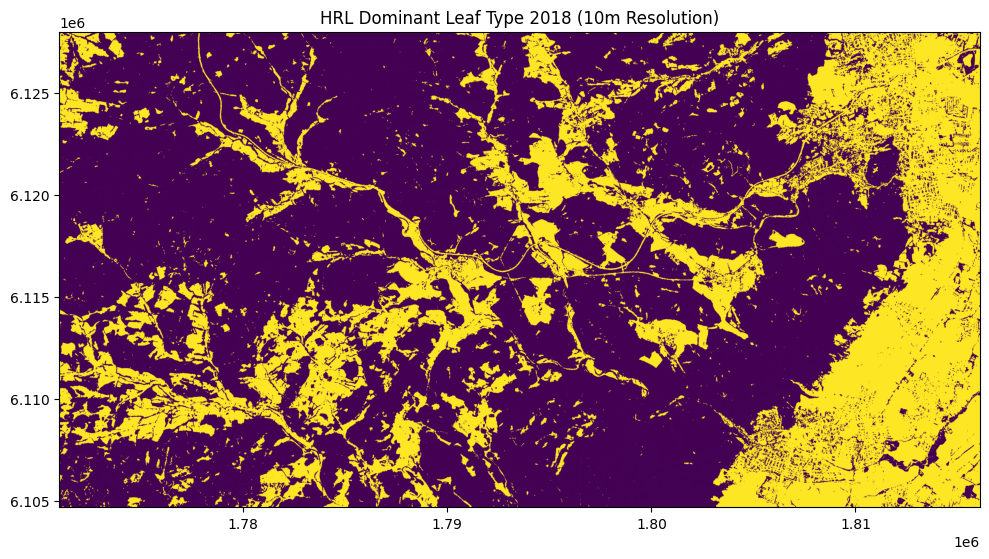

ROI 5: Width: 4270 pixels, Height: 2330 pixels
GeoTIFF saved to: /content/drive/MyDrive/Forest_AI_Data/leaf_type_data_10m_5.tif
CRS: EPSG:3857
Transform: | 10.00, 0.00, 1029700.00|
| 0.00,-10.00, 6444500.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=1029700.0, bottom=6421200.0, right=1072400.0, top=6444500.0)
Resolution X: 10.0 meters
Resolution Y: 10.0 meters
Shape: (2330, 4270)


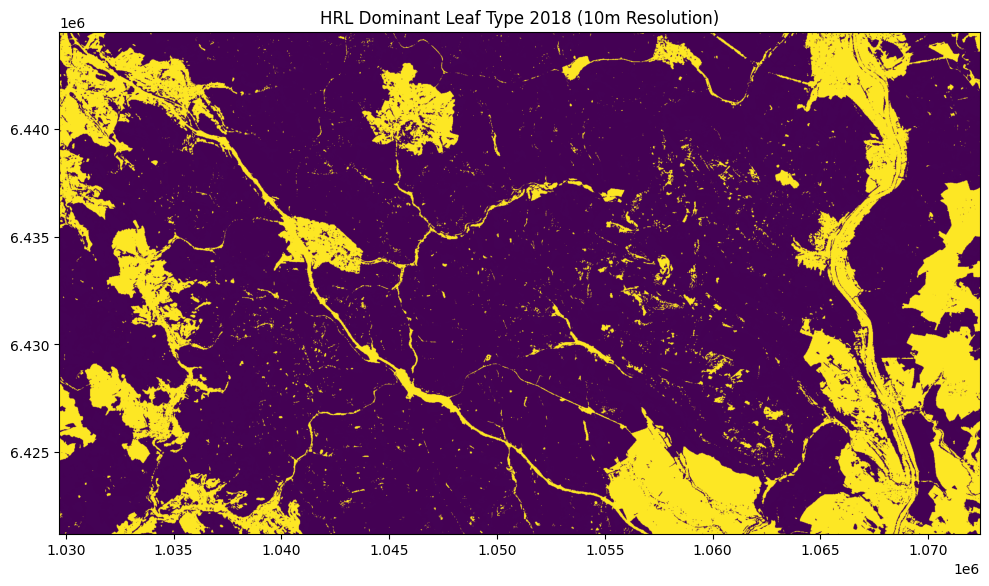

In [ ]:
# WORKS
projection = 3857 # natively this API has 3035
# ArcGIS ImageServer URL
server_url = "https://copernicus.discomap.eea.europa.eu/arcgis/rest/services/GioLandPublic/HRL_DominanteLeafType_2018/ImageServer/exportImage"

for roi, bbox in enumerate(bounding_box):

  # Calculate dimensions for 10m pixel size
  bbox_width = bbox[2] - bbox[0]  # x_max - x_min
  bbox_height = bbox[3] - bbox[1]  # y_max - y_min

  # Calculate the number of pixels needed for 10m resolution
  width_pixels = math.ceil(bbox_width / 10)
  height_pixels = math.ceil(bbox_height / 10)

  print(f"ROI {roi}: Width: {width_pixels} pixels, Height: {height_pixels} pixels")

  # Set up the request params
  params = {
      "bbox": ",".join(map(str, bbox)),
      "bboxSR": "EPSG:3035",
      "imageSR": projection,
      "size": f"{width_pixels},{height_pixels}",  # Dynamic size based on 10m resolution
      "format": "tiff",
      "pixelType": "U8",
      "noData": "",
      "interpolation": "RSP_NearestNeighbor",
      "compression": "",
      "compressionQuality": 75,
      "bandIds": "",
      "mosaicRule": "",
      "renderingRule": "",
      "f": "json"
  }

  # Send request for JSON response
  response = requests.get(server_url, params=params)
  data = response.json()

  if 'href' in data:
      # Get the actual image from the URL provided in the JSON response
      image_url = data['href']
      image_response = requests.get(image_url)

      # Save the GeoTIFF directly to Google Drive
      save_path = f'/content/drive/MyDrive/Forest_AI_Data/leaf_type_data_10m_{roi}.tif'
      with open(save_path, 'wb') as f:
          f.write(image_response.content)
      print(f"GeoTIFF saved to: {save_path}")

      # Open and examine the saved GeoTIFF with rasterio
      with rasterio.open(save_path) as src:
          print(f"CRS: {src.crs}")
          print(f"Transform: {src.transform}")
          print(f"Bounds: {src.bounds}")
          print(f"Resolution X: {src.transform[0]} meters")  # Should be close to 10
          print(f"Resolution Y: {-src.transform[4]} meters")  # Should be close to 10
          print(f"Shape: {src.shape}")

          # Plot with proper georeferencing
          fig, ax = plt.subplots(figsize=(10, 10))
          show(src, ax=ax)
          plt.title("HRL Dominant Leaf Type 2018 (10m Resolution)")
          plt.tight_layout()
          plt.show()
  else:
      print("Error: Could not get image URL from response")
      print(data)  # Print the response for debugging

In [ ]:
for i in range(len(bounding_box)):
  # Open and examine the saved GeoTIFF
  with rasterio.open(f"/content/drive/MyDrive/Forest_AI_Data/leaf_type_data_10m_{i}.tif") as src:
      print(f"Region {i}:")
      print(f"CRS: {src.crs}")
      print(f"Transform: \n{src.transform}")
      print(f"Bounds: {src.bounds}")
      print(f"Shape: {src.shape}\n")


Region 0:
CRS: EPSG:3857
Transform: 
| 10.00, 0.00, 931000.00|
| 0.00,-10.00, 6232800.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=931000.0, bottom=6208000.0, right=972100.0, top=6232800.0)
Shape: (2480, 4110)

Region 1:
CRS: EPSG:3857
Transform: 
| 10.00, 0.00, 1443000.00|
| 0.00,-10.00, 6319000.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=1443000.0, bottom=6300000.0, right=1484000.0, top=6319000.0)
Shape: (1900, 4100)

Region 2:
CRS: EPSG:3857
Transform: 
| 10.00, 0.00, 1310400.00|
| 0.00,-10.00, 6143100.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=1310400.0, bottom=6112900.0, right=1358500.0, top=6143100.0)
Shape: (3020, 4810)

Region 3:
CRS: EPSG:3857
Transform: 
| 10.00, 0.00, 1581700.00|
| 0.00,-10.00, 6103600.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=1581700.0, bottom=6082700.0, right=1624400.0, top=6103600.0)
Shape: (2090, 4270)

Region 4:
CRS: EPSG:3857
Transform: 
| 10.00, 0.00, 1771000.00|
| 0.00,-10.00, 6128000.00|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(

##Clip target image

In [ ]:
for i in range(len(bounding_box)):
  target_path = f"/content/drive/MyDrive/Forest_AI_Data/leaf_type_data_10m_{i}.tif"
  mask_path = f"/content/drive/MyDrive/Forest_AI_Data/masks/mask_aoi_3857_{i}.shp"

  ds_target = gdal.Open(target_path)
  target_array = ds_target.ReadAsArray()
  print(f"Region {i} Before clipping:")
  print(ds_target.GetGeoTransform())
  print(target_array.shape)

  if i == 0:
    ds_target_clip_0 = gdal.Warp(f"target_clip_{i}.tif", ds_target, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    target_array_clip_0 = ds_target_clip_0.ReadAsArray()
    print(f"Region {i} After clipping:")
    print(ds_target_clip_0.GetGeoTransform())
    print(target_array_clip_0.shape, "\n")
  elif i == 1:
    ds_target_clip_1 = gdal.Warp(f"target_clip_{i}.tif", ds_target, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    target_array_clip_1 = ds_target_clip_1.ReadAsArray()
    print(f"Region {i} After clipping:")
    print(ds_target_clip_1.GetGeoTransform())
    print(target_array_clip_1.shape, "\n")
  elif i == 2:
    ds_target_clip_2 = gdal.Warp(f"target_clip_{i}.tif", ds_target, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    target_array_clip_2 = ds_target_clip_2.ReadAsArray()
    print(f"Region {i} After clipping:")
    print(ds_target_clip_2.GetGeoTransform())
    print(target_array_clip_2.shape, "\n")
  elif i == 3:
    ds_target_clip_3 = gdal.Warp(f"target_clip_{i}.tif", ds_target, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    target_array_clip_3 = ds_target_clip_3.ReadAsArray()
    print(f"Region {i} After clipping:")
    print(ds_target_clip_3.GetGeoTransform())
    print(target_array_clip_3.shape, "\n")
  elif i == 4:
    ds_target_clip_4 = gdal.Warp(f"target_clip_{i}.tif", ds_target, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    target_array_clip_4 = ds_target_clip_4.ReadAsArray()
    print(f"Region {i} After clipping:")
    print(ds_target_clip_4.GetGeoTransform())
    print(target_array_clip_4.shape, "\n")
  else:
    ds_target_clip_5 = gdal.Warp(f"target_clip_{i}.tif", ds_target, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    target_array_clip_5 = ds_target_clip_5.ReadAsArray()
    print(f"Region {i} After clipping:")
    print(ds_target_clip_5.GetGeoTransform())
    print(target_array_clip_5.shape, "\n")

/usr/local/lib/python3.11/dist-packages/osgeo/gdal.py:312: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


Region 0 Before clipping:
(931000.0, 10.0, 0.0, 6232800.0, 0.0, -10.0)
(2480, 4110)
Region 0 After clipping:
(932590.0, 10.0, 0.0, 6231920.0, 0.0, -10.0)
(1644, 3194) 

Region 1 Before clipping:
(1443000.0, 10.0, 0.0, 6319000.0, 0.0, -10.0)
(1900, 4100)
Region 1 After clipping:
(1447500.0, 10.0, 0.0, 6317150.0, 0.0, -10.0)
(1644, 3195) 

Region 2 Before clipping:
(1310400.0, 10.0, 0.0, 6143100.0, 0.0, -10.0)
(3020, 4810)
Region 2 After clipping:
(1316870.0, 10.0, 0.0, 6135260.0, 0.0, -10.0)
(1644, 3194) 

Region 3 Before clipping:
(1581700.0, 10.0, 0.0, 6103600.0, 0.0, -10.0)
(2090, 4270)
Region 3 After clipping:
(1586470.0, 10.0, 0.0, 6098720.0, 0.0, -10.0)
(1644, 3194) 

Region 4 Before clipping:
(1771000.0, 10.0, 0.0, 6128000.0, 0.0, -10.0)
(2330, 4510)
Region 4 After clipping:
(1775820.0, 10.0, 0.0, 6127210.0, 0.0, -10.0)
(1644, 3194) 

Region 5 Before clipping:
(1029700.0, 10.0, 0.0, 6444500.0, 0.0, -10.0)
(2330, 4270)
Region 5 After clipping:
(1032420.0, 10.0, 0.0, 6441800.0, 0.0

##Clean and inspect target array

In [ ]:
for i in range(len(bounding_box)):
  drop_count = 42 # Number of rows and columns to drop
  if i == 0:
    clean_target_array_0 = target_array_clip_0[drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", target_array_clip_0)
    print("Array after dropping rows and columns:\n", clean_target_array_0)
  elif i == 1:
    clean_target_array_1 = target_array_clip_1[drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", target_array_clip_1)
    print("Array after dropping rows and columns:\n", clean_target_array_1)
  elif i == 2:
    clean_target_array_2 = target_array_clip_2[drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", target_array_clip_2)
    print("Array after dropping rows and columns:\n", clean_target_array_2)
  elif i == 3:
    clean_target_array_3 = target_array_clip_3[drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", target_array_clip_3)
    print("Array after dropping rows and columns:\n", clean_target_array_3)
  elif i == 4:
    clean_target_array_4 = target_array_clip_4[drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", target_array_clip_4)
    print("Array after dropping rows and columns:\n", clean_target_array_4)
  else:
    clean_target_array_5 = target_array_clip_5[drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", target_array_clip_5)
    print("Array after dropping rows and columns:\n", clean_target_array_5)

Original array:
 [[0 0 2 ... 0 0 0]
 [0 0 2 ... 0 0 0]
 [0 0 2 ... 0 0 0]
 ...
 [0 0 0 ... 2 0 0]
 [0 0 0 ... 2 0 0]
 [0 0 0 ... 2 0 0]]
Array after dropping rows and columns:
 [[  2   2   2 ... 240 240 240]
 [  2   2   2 ... 240 240 240]
 [  2   2   2 ... 240 240 240]
 ...
 [  2   2   2 ...   2   2   2]
 [  2   2   2 ...   2   2   2]
 [  2   2   2 ...   2   2   2]]
Original array:
 [[  0   0 240 ...   0   0   0]
 [  0   0 240 ...   0   0   0]
 [  0   0 240 ...   0   0   0]
 ...
 [  0   0   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]
 [  0   0   0 ...   0   0   0]]
Array after dropping rows and columns:
 [[240 240   1 ...   2   2   2]
 [240   1   2 ...   2   2   2]
 [  1   1   2 ...   2   2   2]
 ...
 [  2   2   2 ...   2   2   2]
 [  2   2   2 ...   2   2   2]
 [  2   2   2 ...   2   2   2]]
Original array:
 [[  0   0 240 ...   0   0   0]
 [  0   0 240 ...   0   0   0]
 [  0   0 240 ...   0   0   0]
 ...
 [  0   0   0 ...   2   0   0]
 [  0   0   0 ...   2   0   0]
 [  0   0   0

In [ ]:
# insert the array you want to check
arr_to_check = clean_target_array_5

if 240 in arr_to_check:
    print("The array contains the value 240.")
    count_240 = np.sum(arr_to_check == 240)
    print("The number of 240 values in the array is:", count_240)
else:
    print("The array does not contain the value 240.")

if 0 in arr_to_check:
    print("The array contains the value 0.")
    count_240 = np.sum(arr_to_check == 0)
    print("The number of 0 values in the array is:", count_240)
else:
    print("The array does not contain the value 0.")

The array contains the value 240.
The number of 240 values in the array is: 501071
The array does not contain the value 0.


In [ ]:
#trimm
def match_to_smallest_shape(arr0, arr1, arr2, arr3, arr4, arr5):
    # Extract height and width from each array
    h0, w0 = arr0.shape
    h1, w1 = arr1.shape
    h2, w2 = arr2.shape
    h3, w3 = arr3.shape
    h4, w4 = arr4.shape
    h5, w5 = arr5.shape

    # Find the minimum height and width
    min_h = min(h0, h1, h2, h3, h4, h5)
    min_w = min(w0, w1, w2, w3, w4, w5)


    # Trim function: assumes shape is (bands, height, width)
    def trim(arr, h, w):
        return arr[:h, :w]

    # Apply trimming
    arr0_trimmed = trim(arr0, min_h, min_w)
    arr1_trimmed = trim(arr1, min_h, min_w)
    arr2_trimmed = trim(arr2, min_h, min_w)
    arr3_trimmed = trim(arr3, min_h, min_w)
    arr4_trimmed = trim(arr4, min_h, min_w)
    arr5_trimmed = trim(arr5, min_h, min_w)

    return arr0_trimmed, arr1_trimmed, arr2_trimmed, arr3_trimmed, arr4_trimmed, arr5_trimmed

trimm_target_array_0, trimm_target_array_1, trimm_target_array_2, trimm_target_array_3, trimm_target_array_4,  trimm_target_array_5 = match_to_smallest_shape(clean_target_array_0, clean_target_array_1, clean_target_array_2, clean_target_array_3, clean_target_array_4, clean_target_array_5)
print(trimm_target_array_0.shape)
print(trimm_target_array_1.shape)
print(trimm_target_array_2.shape)
print(trimm_target_array_3.shape)
print(trimm_target_array_4.shape)
print(trimm_target_array_5.shape)

(1560, 3110)
(1560, 3110)
(1560, 3110)
(1560, 3110)
(1560, 3110)
(1560, 3110)


In [ ]:
trimm_target_array_0[trimm_target_array_0 == 240] = 0
trimm_target_array_1[trimm_target_array_1 == 240] = 0
trimm_target_array_2[trimm_target_array_2 == 240] = 0
trimm_target_array_3[trimm_target_array_3 == 240] = 0
trimm_target_array_4[trimm_target_array_4 == 240] = 0
trimm_target_array_5[trimm_target_array_5 == 240] = 0

0 = No Forest, 1 = Deciduous, 2 = Coniferous

Unique values and their distribution for trimm_target_array_0:
Value: 0, Count: 604725
Value: 1, Count: 463051
Value: 2, Count: 3783824


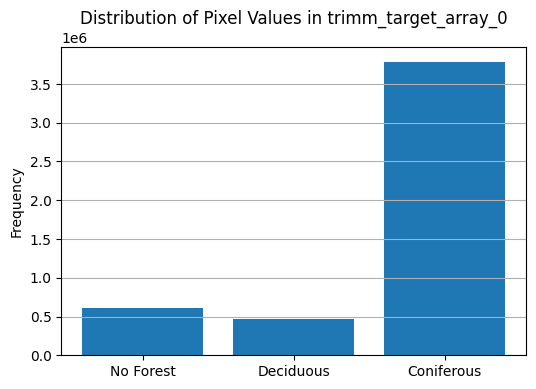


Unique values and their distribution for trimm_target_array_1:
Value: 0, Count: 870287
Value: 1, Count: 443641
Value: 2, Count: 3537672


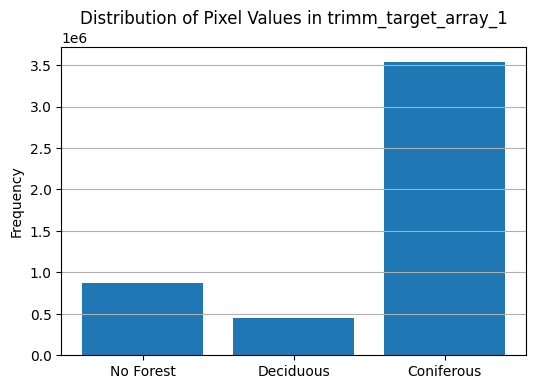


Unique values and their distribution for trimm_target_array_2:
Value: 0, Count: 2078078
Value: 1, Count: 729680
Value: 2, Count: 2043842


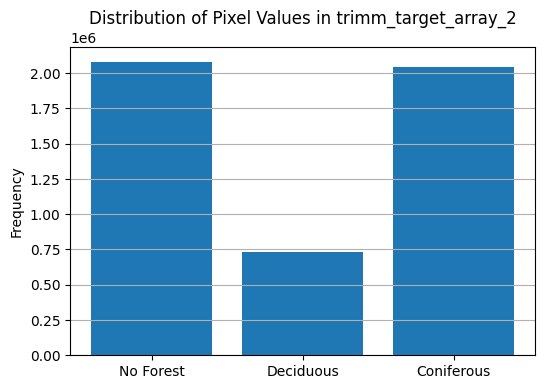


Unique values and their distribution for trimm_target_array_3:
Value: 0, Count: 1290586
Value: 1, Count: 2485044
Value: 2, Count: 1075970


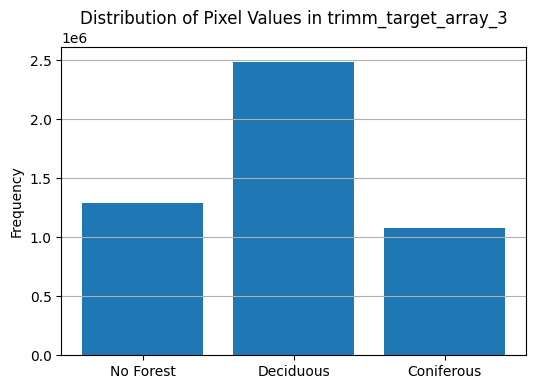


Unique values and their distribution for trimm_target_array_4:
Value: 0, Count: 1137746
Value: 1, Count: 3119944
Value: 2, Count: 593910


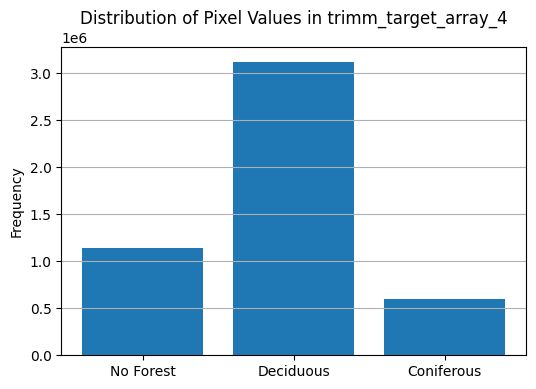


Unique values and their distribution for trimm_target_array_5:
Value: 0, Count: 501071
Value: 1, Count: 3062657
Value: 2, Count: 1287872


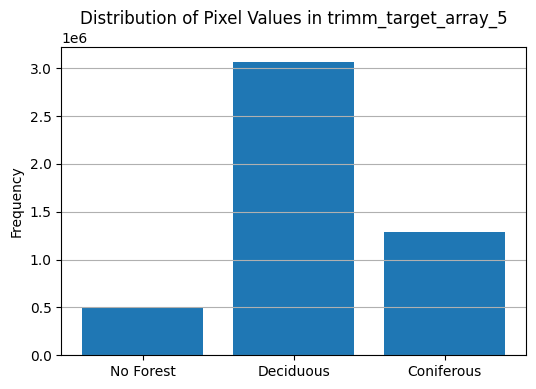

Unique values and their distribution across all trimmed target arrays:
Value: 0, Count: 5877768
Value: 1, Count: 9840966
Value: 2, Count: 8539266


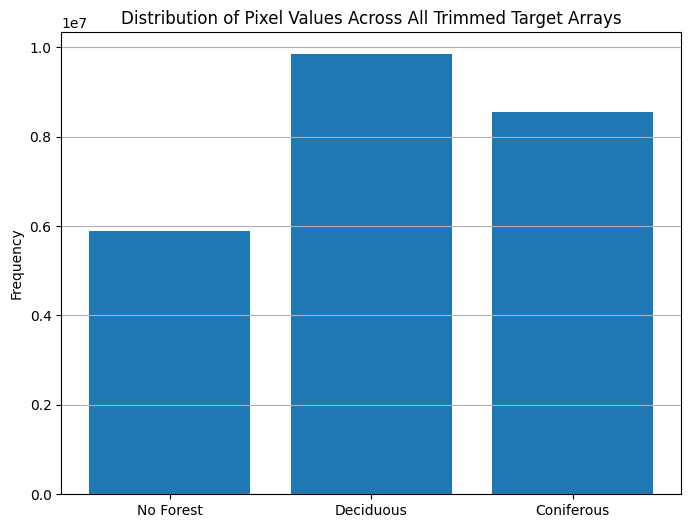

In [ ]:
# Get unique values and their counts
unique_values_0, counts_0 = np.unique(trimm_target_array_0, return_counts=True)

# Print the unique values and their counts for array 0
print("Unique values and their distribution for trimm_target_array_0:")
for value, count in zip(unique_values_0, counts_0):
    print(f"Value: {value}, Count: {count}")

# Visualize the distribution for array 0
plt.figure(figsize=(6, 4))
plt.bar(unique_values_0, counts_0)
plt.ylabel("Frequency")
plt.title("Distribution of Pixel Values in trimm_target_array_0")
plt.xticks(unique_values_0, ['No Forest', 'Deciduous', 'Coniferous']) # Added labels here
plt.grid(axis='y')
plt.show()

# Do the same for the other trimmed arrays
unique_values_1, counts_1 = np.unique(trimm_target_array_1, return_counts=True)
print("\nUnique values and their distribution for trimm_target_array_1:")
for value, count in zip(unique_values_1, counts_1):
    print(f"Value: {value}, Count: {count}")

# Visualize the distribution for array 1
plt.figure(figsize=(6, 4))
plt.bar(unique_values_1, counts_1)
plt.ylabel("Frequency")
plt.title("Distribution of Pixel Values in trimm_target_array_1")
plt.xticks(unique_values_1, ['No Forest', 'Deciduous', 'Coniferous']) # Added labels here
plt.grid(axis='y')
plt.show()

unique_values_2, counts_2 = np.unique(trimm_target_array_2, return_counts=True)
print("\nUnique values and their distribution for trimm_target_array_2:")
for value, count in zip(unique_values_2, counts_2):
    print(f"Value: {value}, Count: {count}")

# Visualize the distribution for array 2
plt.figure(figsize=(6, 4))
plt.bar(unique_values_2, counts_2)
plt.ylabel("Frequency")
plt.title("Distribution of Pixel Values in trimm_target_array_2")
plt.xticks(unique_values_2, ['No Forest', 'Deciduous', 'Coniferous']) # Added labels here
plt.grid(axis='y')
plt.show()

unique_values_3, counts_3 = np.unique(trimm_target_array_3, return_counts=True)
print("\nUnique values and their distribution for trimm_target_array_3:")
for value, count in zip(unique_values_3, counts_3):
    print(f"Value: {value}, Count: {count}")

# Visualize the distribution for array 3
plt.figure(figsize=(6, 4))
plt.bar(unique_values_3, counts_3)
plt.ylabel("Frequency")
plt.title("Distribution of Pixel Values in trimm_target_array_3")
plt.xticks(unique_values_3, ['No Forest', 'Deciduous', 'Coniferous']) # Added labels here
plt.grid(axis='y')
plt.show()

unique_values_4, counts_4 = np.unique(trimm_target_array_4, return_counts=True)
print("\nUnique values and their distribution for trimm_target_array_4:")
for value, count in zip(unique_values_4, counts_4):
    print(f"Value: {value}, Count: {count}")

# Visualize the distribution for array 4
plt.figure(figsize=(6, 4))
plt.bar(unique_values_4, counts_4)
plt.ylabel("Frequency")
plt.title("Distribution of Pixel Values in trimm_target_array_4")
plt.xticks(unique_values_4, ['No Forest', 'Deciduous', 'Coniferous']) # Added labels here
plt.grid(axis='y')
plt.show()

unique_values_5, counts_5 = np.unique(trimm_target_array_5, return_counts=True)
print("\nUnique values and their distribution for trimm_target_array_5:")
for value, count in zip(unique_values_5, counts_5):
    print(f"Value: {value}, Count: {count}")

# Visualize the distribution for array 5
plt.figure(figsize=(6, 4))
plt.bar(unique_values_5, counts_5)
plt.ylabel("Frequency")
plt.title("Distribution of Pixel Values in trimm_target_array_5")
plt.xticks(unique_values_5, ['No Forest', 'Deciduous', 'Coniferous']) # Added labels here
plt.grid(axis='y')
plt.show()
# Show overall unique values
# Concatenate all trimmed target arrays
all_trimmed_target_arrays = np.concatenate([trimm_target_array_0.flatten(),
                                            trimm_target_array_1.flatten(),
                                            trimm_target_array_2.flatten(),
                                            trimm_target_array_3.flatten(),
                                            trimm_target_array_4.flatten(),
                                            trimm_target_array_5.flatten()])

# Get unique values and their counts from the concatenated array
unique_values_all, counts_all = np.unique(all_trimmed_target_arrays, return_counts=True)

# Print the unique values and their counts
print("Unique values and their distribution across all trimmed target arrays:")
for value, count in zip(unique_values_all, counts_all):
    print(f"Value: {value}, Count: {count}")

# Visualize the distribution
plt.figure(figsize=(8, 6))
plt.bar(unique_values_all, counts_all)
plt.ylabel("Frequency")
plt.title("Distribution of Pixel Values Across All Trimmed Target Arrays")
plt.xticks(unique_values_all, ['No Forest', 'Deciduous', 'Coniferous']) # Added labels here
plt.grid(axis='y')
plt.show()

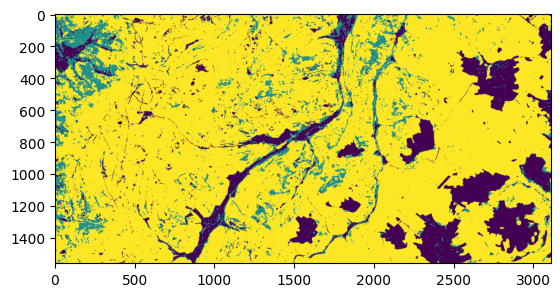

In [ ]:
plt.imshow(trimm_target_array_0)

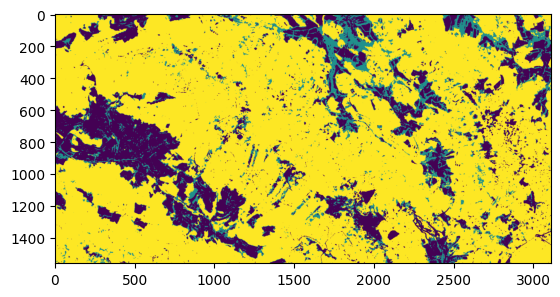

In [ ]:
plt.imshow(trimm_target_array_1)

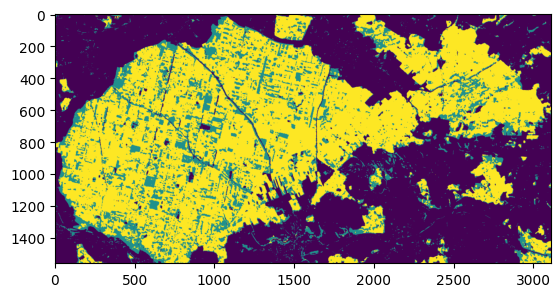

In [ ]:
plt.imshow(trimm_target_array_2)

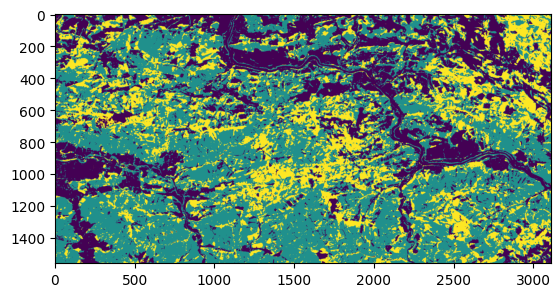

In [ ]:
plt.imshow(trimm_target_array_3)

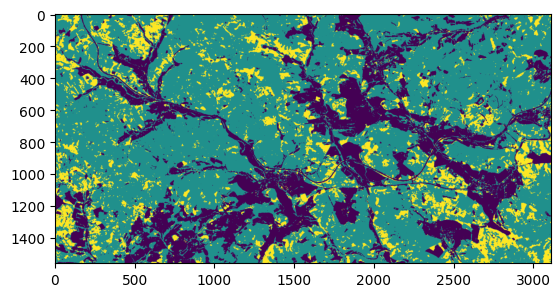

In [ ]:
plt.imshow(trimm_target_array_4)

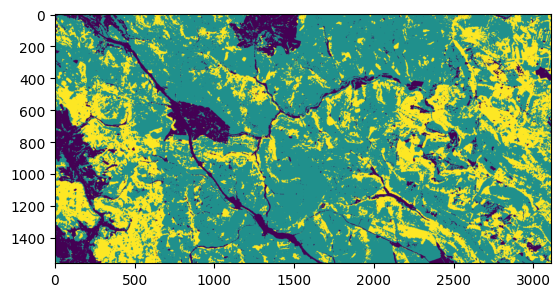

In [ ]:
plt.imshow(trimm_target_array_5)

In [ ]:
trimm_target_array_0 = np.expand_dims(trimm_target_array_0, axis=-1)
trimm_target_array_1 = np.expand_dims(trimm_target_array_1, axis=-1)
trimm_target_array_2 = np.expand_dims(trimm_target_array_2, axis=-1)
trimm_target_array_3 = np.expand_dims(trimm_target_array_3, axis=-1)
trimm_target_array_4 = np.expand_dims(trimm_target_array_4, axis=-1)
trimm_target_array_5 = np.expand_dims(trimm_target_array_5, axis=-1)
print(trimm_target_array_0.shape)
print(trimm_target_array_1.shape)
print(trimm_target_array_2.shape)
print(trimm_target_array_3.shape)
print(trimm_target_array_4.shape)
print(trimm_target_array_5.shape)

(1560, 3110, 1)
(1560, 3110, 1)
(1560, 3110, 1)
(1560, 3110, 1)
(1560, 3110, 1)
(1560, 3110, 1)


In [ ]:
# save target arrays
# Save as .npy files
np.save('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_0.npy', trimm_target_array_0)
np.save('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_1.npy', trimm_target_array_1)
np.save('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_2.npy', trimm_target_array_2)
np.save('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_3.npy', trimm_target_array_3)
np.save('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_4.npy', trimm_target_array_4)
np.save('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_5.npy', trimm_target_array_5)

#Training Data

## Fetch Training Image

In [ ]:
# Earth Engine is installed by default in Google Colab, therfore it only needs to be imported and authenticated. This needs to be done for every colab session after restarting the kernel.

#Import Earth Engine
import ee
#Trigger the authentification flow.
ee.Authenticate()
#Initialize the library
ee.Initialize(project='deepforest-457313')

AOIs:

[1316231, 6118182, 1349201, 6135955] Ebersberg original <br>
[1310456,6112984, 1358458,6143071] Ebersberg 2 (groß) <br>
[1463002,6106516, 1505904,6134358] Kobernaußer Wald, abgeschnittense Satelliten bild, shape abweichung +1<br>
[1440811,6300438, 1480275,6319146] Bayerischer Wald, shape Abweichung -1 Höhe<br>
[1443000,6300000, 1484000,6319000] Bayerischer Wald, shape Abweichung +1 Breite <br>
[932253,6218062, 975657,6249409] Schwarzwald, shape Abweichung +1 Breite<br>
[931000,6208000, 972100,6232800] Schwarzwald_adjusted, works <br>
[1581700,6082700, 1624400,6103600] Oberösterreichische Kalkalpen <br>
[1771000,6104700, 1816174,6128000] Wien <br>
[1029700,6421200, 1072400,6444500] Würzburg

In [ ]:
projection = 'EPSG:3857'

for roi, bbox in enumerate(bounding_box):
  # Convert the bounding box list to an ee.Geometry.Rectangle object
  aoi = ee.Geometry.Rectangle(bbox, projection, False)

  # Define date range
  start_date = '2018-06-01'
  end_date = '2018-09-30'

  # Load Sentinel-2 SR collection
  collection = (
      ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
      .filterBounds(aoi)
      .filterDate(start_date, end_date)
      .sort("CLOUDY_PIXEL_PERCENTAGE")
  )

  # Select first image (least cloudy)
  image = collection.first()

  # Define bands
  bands_10m = ['B2', 'B3', 'B4', 'B8']
  bands_20m = ['B5', 'B6', 'B7', 'B8A', 'B11', 'B12']
  bands_60m = ['B9']

  # Calculate NDVI (Near Infrared - Red) / (Near Infrared + Red)
  # Sentinel-2 bands: B8 is Near Infrared (NIR), B4 is Red
  ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')

  # Resample all bands to 10m using nearest neighbor and cast to Float32
  image_10m = image.select(bands_10m).reproject(crs=projection, scale=10).toFloat()
  resampled_20m = image.select(bands_20m).resample('bicubic').reproject(crs=projection, scale=10).toFloat()
  resampled_60m = image.select(bands_60m).resample('bicubic').reproject(crs=projection, scale=10).toFloat()
  # Resample NDVI to 10m
  ndvi_10m = ndvi.reproject(crs=projection, scale=10).toFloat()


  # Combine and select all bands explicitly, including NDVI
  combined_image = ee.Image.cat([
      image_10m,
      resampled_20m,
      resampled_60m,
      ndvi_10m # Add NDVI here
  ]).select(bands_10m + bands_20m + bands_60m + ['NDVI']) # Add NDVI to the band selection

  # Create region around the center point
  region = aoi.buffer(320).bounds()

  # Export to Google Drive, with unique file name
  task = ee.batch.Export.image.toDrive(
      image=combined_image,
      description=f'Sentinel2_Tile_10m_{roi}',  # Add index to description
      folder='Forest_AI_Data',
      fileNamePrefix=f'sentinel_ndvi_tile_10m_{roi}', # Add index to file name
      region=region,
      scale=10,
      crs=projection,
      #dimensions="640x640", the scale parameter and the dimensions parameter cannot both be used simoltaniously
      maxPixels=1e9
  )
  task.start()
  print(f'Task {roi} started. Check your Google Drive for progress.')

Task 0 started. Check your Google Drive for progress.
Task 1 started. Check your Google Drive for progress.
Task 2 started. Check your Google Drive for progress.
Task 3 started. Check your Google Drive for progress.
Task 4 started. Check your Google Drive for progress.
Task 5 started. Check your Google Drive for progress.


## Clip training image

In [ ]:
for i in range(len(bounding_box)):
  train_path = f"/content/drive/MyDrive/Forest_AI_Data/sentinel_ndvi_tile_10m_{i}.tif"
  mask_path = f"/content/drive/MyDrive/Forest_AI_Data/masks/mask_aoi_3857_{i}.shp"

  ds_train = gdal.Open(train_path)
  train_array = ds_train.ReadAsArray()
  print(f"Region {i} Train Before clipping:")
  print(ds_train.GetGeoTransform())
  print(train_array.shape, "\n")
  if i == 0:
    ds_train_clip_0 = gdal.Warp(f"train_clip_{i}.tif", ds_train, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    train_array_clip_0 = ds_train_clip_0.ReadAsArray()
  elif i == 1:
    ds_train_clip_1 = gdal.Warp(f"train_clip_{i}.tif", ds_train, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    train_array_clip_1 = ds_train_clip_1.ReadAsArray()
  elif i == 2:
    ds_train_clip_2 = gdal.Warp(f"train_clip_{i}.tif", ds_train, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    train_array_clip_2 = ds_train_clip_2.ReadAsArray()
  elif i == 3:
    ds_train_clip_3 = gdal.Warp(f"train_clip_{i}.tif", ds_train, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    train_array_clip_3 = ds_train_clip_3.ReadAsArray()
  elif i == 4:
    ds_train_clip_4 = gdal.Warp(f"train_clip_{i}.tif", ds_train, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    train_array_clip_4 = ds_train_clip_4.ReadAsArray()
  else:
    ds_train_clip_5 = gdal.Warp(f"train_clip_{i}.tif", ds_train, cutlineDSName = mask_path, cropToCutline = True, dstNodata = np.nan)
    train_array_clip_5 = ds_train_clip_5.ReadAsArray()

Region 0 Train Before clipping:
(930510.0, 10.0, 0.0, 6233290.0, 0.0, -10.0)
(12, 2578, 4208) 

Region 1 Train Before clipping:
(1442500.0, 10.0, 0.0, 6319500.0, 0.0, -10.0)
(12, 2000, 4200) 

Region 2 Train Before clipping:
(1309910.0, 10.0, 0.0, 6143590.0, 0.0, -10.0)
(12, 3117, 4908) 

Region 3 Train Before clipping:
(1581220.0, 10.0, 0.0, 6104090.0, 0.0, -10.0)
(12, 2187, 4366) 

Region 4 Train Before clipping:
(1770510.0, 10.0, 0.0, 6128490.0, 0.0, -10.0)
(12, 2427, 4615) 

Region 5 Train Before clipping:
(1029200.0, 10.0, 0.0, 6445010.0, 0.0, -10.0)
(12, 2431, 4370) 



In [ ]:
# Comparing shapes and origins | region 0
print("Region 0 Train After clipping:")
print(ds_train_clip_0.GetGeoTransform())
print(train_array_clip_0.shape)
print("Region 0 Target After clipping:")
print(ds_target_clip_0.GetGeoTransform())
print(target_array_clip_0.shape, "\n")
# region 1
print("Region 1 Train After clipping:")
print(ds_train_clip_1.GetGeoTransform())
print(train_array_clip_1.shape)
print("Region 1 Target After clipping:")
print(ds_target_clip_1.GetGeoTransform())
print(target_array_clip_1.shape, "\n")
# region 2
print("Region 2 Train After clipping:")
print(ds_train_clip_2.GetGeoTransform())
print(train_array_clip_2.shape)
print("Region 2 Target After clipping:")
print(ds_target_clip_2.GetGeoTransform())
print(target_array_clip_2.shape, "\n")
# region 3
print("Region 3 Train After clipping:")
print(ds_train_clip_3.GetGeoTransform())
print(train_array_clip_3.shape)
print("Region 3 Target After clipping:")
print(ds_target_clip_3.GetGeoTransform())
print(target_array_clip_3.shape, "\n")
# region 4
print("Region 4 Train After clipping:")
print(ds_train_clip_4.GetGeoTransform())
print(train_array_clip_4.shape)
print("Region 4 Target After clipping:")
print(ds_target_clip_4.GetGeoTransform())
print(target_array_clip_4.shape, "\n")
# region 5
print("Region 5 Train After clipping:")
print(ds_train_clip_5.GetGeoTransform())
print(train_array_clip_5.shape)
print("Region 5 Target After clipping:")
print(ds_target_clip_5.GetGeoTransform())
print(target_array_clip_5.shape, "\n")

Region 0 Train After clipping:
(932590.0, 10.0, 0.0, 6231920.0, 0.0, -10.0)
(12, 1644, 3194)
Region 0 Target After clipping:
(932590.0, 10.0, 0.0, 6231920.0, 0.0, -10.0)
(1644, 3194) 

Region 1 Train After clipping:
(1447500.0, 10.0, 0.0, 6317150.0, 0.0, -10.0)
(12, 1644, 3195)
Region 1 Target After clipping:
(1447500.0, 10.0, 0.0, 6317150.0, 0.0, -10.0)
(1644, 3195) 

Region 2 Train After clipping:
(1316870.0, 10.0, 0.0, 6135260.0, 0.0, -10.0)
(12, 1644, 3194)
Region 2 Target After clipping:
(1316870.0, 10.0, 0.0, 6135260.0, 0.0, -10.0)
(1644, 3194) 

Region 3 Train After clipping:
(1586470.0, 10.0, 0.0, 6098720.0, 0.0, -10.0)
(12, 1644, 3194)
Region 3 Target After clipping:
(1586470.0, 10.0, 0.0, 6098720.0, 0.0, -10.0)
(1644, 3194) 

Region 4 Train After clipping:
(1775820.0, 10.0, 0.0, 6127210.0, 0.0, -10.0)
(12, 1644, 3194)
Region 4 Target After clipping:
(1775820.0, 10.0, 0.0, 6127210.0, 0.0, -10.0)
(1644, 3194) 

Region 5 Train After clipping:
(1032420.0, 10.0, 0.0, 6441800.0, 0.

#Clean and Normalize, and inspect Arrays<br>
removing those black no data values on the sides

In [ ]:
for i in range(len(bounding_box)):
  drop_count = 42 # Number of rows and columns to drop
  if i == 0:
    clean_train_array_0 = train_array_clip_0[:, drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", train_array_clip_0)
    print("Array after dropping rows and columns:\n", clean_train_array_0)
  elif i == 1:
    clean_train_array_1 = train_array_clip_1[:, drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", train_array_clip_1)
    print("Array after dropping rows and columns:\n", clean_train_array_1)
  elif i == 2:
    clean_train_array_2 = train_array_clip_2[:, drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", train_array_clip_2)
    print("Array after dropping rows and columns:\n", clean_train_array_2)
  elif i == 3:
    clean_train_array_3 = train_array_clip_3[:, drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", train_array_clip_3)
    print("Array after dropping rows and columns:\n", clean_train_array_3)
  elif i == 4:
    clean_train_array_4 = train_array_clip_4[:, drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", train_array_clip_4)
    print("Array after dropping rows and columns:\n", clean_train_array_4)
  else:
    clean_train_array_5 = train_array_clip_5[:, drop_count:-drop_count, drop_count:-drop_count]
    print("Original array:\n", train_array_clip_5)
    print("Array after dropping rows and columns:\n", clean_train_array_5)

Original array:
 [[[          nan           nan 1.8600000e+02 ...           nan
             nan           nan]
  [          nan           nan 1.2400000e+02 ...           nan
             nan           nan]
  [          nan           nan 1.2400000e+02 ...           nan
             nan           nan]
  ...
  [          nan           nan           nan ... 1.4600000e+02
             nan           nan]
  [          nan           nan           nan ... 1.4600000e+02
             nan           nan]
  [          nan           nan           nan ... 1.5000000e+02
             nan           nan]]

 [[          nan           nan 2.5800000e+02 ...           nan
             nan           nan]
  [          nan           nan 1.7100000e+02 ...           nan
             nan           nan]
  [          nan           nan 1.7100000e+02 ...           nan
             nan           nan]
  ...
  [          nan           nan           nan ... 3.2200000e+02
             nan           nan]
  [          nan   

checking how many zeros are left

In [ ]:
# select wich array to check
arr_to_check = clean_train_array_5
if 240 in arr_to_check:
    print("The array contains the value 240.")
    count_240 = np.sum(arr_to_check == 240)
    print("The number of 240 values in the array is:", count_240)
else:
    print("The array does not contain the value 240.")

if 0 in arr_to_check:
    print("The array contains the value 0.")
    count_240 = np.sum(arr_to_check == 0)
    print("The number of 0 values in the array is:", count_240)
else:
    print("The array does not contain the value 0.")

The array contains the value 240.
The number of 240 values in the array is: 38352
The array contains the value 0.
The number of 0 values in the array is: 49


In [ ]:
def match_to_smallest_shape(arr0, arr1, arr2, arr3, arr4, arr5):
    # Extract height and width from each array
    _, h0, w0 = arr0.shape
    _, h1, w1 = arr1.shape
    _, h2, w2 = arr2.shape
    _, h3, w3 = arr3.shape
    _, h4, w4 = arr4.shape
    _, h5, w5 = arr5.shape

    # Find the minimum height and width
    min_h = min(h0, h1, h2, h3, h4, h5)
    min_w = min(w0, w1, w2, w3, w4, w5)

    # Trim function: assumes shape is (bands, height, width)
    def trim(arr, h, w):
        return arr[:, :h, :w]

    # Apply trimming
    arr0_trimmed = trim(arr0, min_h, min_w)
    arr1_trimmed = trim(arr1, min_h, min_w)
    arr2_trimmed = trim(arr2, min_h, min_w)
    arr3_trimmed = trim(arr3, min_h, min_w)
    arr4_trimmed = trim(arr4, min_h, min_w)
    arr5_trimmed = trim(arr5, min_h, min_w)

    return arr0_trimmed, arr1_trimmed, arr2_trimmed, arr3_trimmed, arr4_trimmed, arr5_trimmed

trimm_train_array_0, trimm_train_array_1, trimm_train_array_2, trimm_train_array_3, trimm_train_array_4, trimm_train_array_5 = match_to_smallest_shape(clean_train_array_0, clean_train_array_1, clean_train_array_2, clean_train_array_3, clean_train_array_4, clean_train_array_5)
print(trimm_train_array_0.shape)
print(trimm_train_array_1.shape)
print(trimm_train_array_2.shape)
print(trimm_train_array_3.shape)
print(trimm_train_array_4.shape)
print(trimm_train_array_5.shape)

(12, 1560, 3110)
(12, 1560, 3110)
(12, 1560, 3110)
(12, 1560, 3110)
(12, 1560, 3110)
(12, 1560, 3110)


In [ ]:
trimm_train_array_2.max()

np.float32(32698.0)

In [ ]:
# Normalizes the array to values between 0 and 1
# np.zeros_like() is a NumPy function. It creates a new array filled with zeros that has the same shape as the input array.
# make sure the array is structured like this (height, width, num_bands)
norm_train_array_0 = np.zeros_like(trimm_train_array_0, dtype=np.float32)
for i in range(trimm_train_array_0.shape[2]):  # For each band
    band = clean_train_array_0[:,:,i]
    norm_train_array_0[:,:,i] = (band - band.min()) / (band.max() - band.min())
norm_train_array_0 = norm_train_array_0.transpose(1, 2, 0)
print("Region 0:")
print("min", norm_train_array_0.min())
print("max", norm_train_array_0.max())
print("shape", norm_train_array_0.shape)
print("dtype", norm_train_array_0.dtype, "\n")

norm_train_array_1 = np.zeros_like(trimm_train_array_1, dtype=np.float32)
for i in range(trimm_train_array_1.shape[2]):  # For each band
    band = clean_train_array_1[:,:,i]
    norm_train_array_1[:,:,i] = (band - band.min()) / (band.max() - band.min())
norm_train_array_1 = norm_train_array_1.transpose(1, 2, 0)
print("Region 1:")
print("min", norm_train_array_1.min())
print("max", norm_train_array_1.max())
print("shape", norm_train_array_1.shape)
print("dtype", norm_train_array_1.dtype, "\n")

norm_train_array_2 = np.zeros_like(trimm_train_array_2, dtype=np.float32)
for i in range(trimm_train_array_2.shape[2]):  # For each band
    band = clean_train_array_2[:,:,i]
    norm_train_array_2[:,:,i] = (band - band.min()) / (band.max() - band.min())
norm_train_array_2 = norm_train_array_2.transpose(1, 2, 0)
print("Region 2:")
print("min", norm_train_array_2.min())
print("max", norm_train_array_2.max())
print("shape", norm_train_array_2.shape)
print("dtype", norm_train_array_2.dtype, "\n")

norm_train_array_3 = np.zeros_like(trimm_train_array_3, dtype=np.float32)
for i in range(trimm_train_array_3.shape[2]):  # For each band
    band = clean_train_array_3[:,:,i]
    norm_train_array_3[:,:,i] = (band - band.min()) / (band.max() - band.min())
norm_train_array_3 = norm_train_array_3.transpose(1, 2, 0)
print("Region 3:")
print("min", norm_train_array_3.min())
print("max", norm_train_array_3.max())
print("shape", norm_train_array_3.shape)
print("dtype", norm_train_array_3.dtype, "\n")

norm_train_array_4 = np.zeros_like(trimm_train_array_4, dtype=np.float32)
for i in range(trimm_train_array_4.shape[2]):  # For each band
    band = clean_train_array_4[:,:,i]
    norm_train_array_4[:,:,i] = (band - band.min()) / (band.max() - band.min())
norm_train_array_4 = norm_train_array_4.transpose(1, 2, 0)
print("Region 4:")
print("min", norm_train_array_4.min())
print("max", norm_train_array_4.max())
print("shape", norm_train_array_4.shape)
print("dtype", norm_train_array_4.dtype, "\n")

norm_train_array_5 = np.zeros_like(trimm_train_array_5, dtype=np.float32)
for i in range(trimm_train_array_5.shape[2]):  # For each band
    band = clean_train_array_5[:,:,i]
    norm_train_array_5[:,:,i] = (band - band.min()) / (band.max() - band.min())
norm_train_array_5 = norm_train_array_5.transpose(1, 2, 0)
print("Region 5:")
print("min", norm_train_array_5.min())
print("max", norm_train_array_5.max())
print("shape", norm_train_array_5.shape)
print("dtype", norm_train_array_5.dtype, "\n")

Region 0:
min 0.0
max 1.0
shape (1560, 3110, 12)
dtype float32 

Region 1:
min 0.0
max 1.0
shape (1560, 3110, 12)
dtype float32 

Region 2:
min 0.0
max 1.0
shape (1560, 3110, 12)
dtype float32 

Region 3:
min 0.0
max 1.0
shape (1560, 3110, 12)
dtype float32 

Region 4:
min 0.0
max 1.0
shape (1560, 3110, 12)
dtype float32 

Region 5:
min 0.0
max 1.0
shape (1560, 3110, 12)
dtype float32 



In [ ]:
# save training arrays as .npy files
np.save('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_0.npy', norm_train_array_0)
np.save('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_1.npy', norm_train_array_1)
np.save('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_2.npy', norm_train_array_2)
np.save('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_3.npy', norm_train_array_3)
np.save('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_4.npy', norm_train_array_4)
np.save('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_5.npy', norm_train_array_5)

##Target Array

In [ ]:
# Load the target arrays
# Y1 is for testing
Y0 = np.load('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_0.npy')
Y1 = np.load('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_1.npy') # Test Lables
Y2 = np.load('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_2.npy')
Y3 = np.load('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_3.npy')
Y4 = np.load('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_4.npy')
Y5 = np.load('/content/drive/MyDrive/Forest_AI_Data/trimm_target_array_5.npy')

In [ ]:
# Load the training arrays
# X1 is for testing
X0 = np.load('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_0.npy')
X1 = np.load('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_1.npy') # Test samples
X2 = np.load('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_2.npy')
X3 = np.load('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_3.npy')
X4 = np.load('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_4.npy')
X5 = np.load('/content/drive/MyDrive/Forest_AI_Data/norm_ndvi_train_array_5.npy')

In [ ]:
test_samples = X1
test_labels = Y1

In [ ]:
# not using 0
# extract patches for training. There is overlap between the patches.
def extract_patches(image, label, patch_size=128, stride=128):
    patches_x, patches_y = [], []
    h, w, _ = image.shape

    for i in range(0, h - patch_size + 1, stride):
        for j in range(0, w - patch_size + 1, stride):
            patch_img = image[i:i+patch_size, j:j+patch_size, :]
            patch_lbl = label[i:i+patch_size, j:j+patch_size]  # shape: (patch_size, patch_size)

            patches_x.append(patch_img)
            patches_y.append(patch_lbl)

    return np.array(patches_x), np.array(patches_y)

x1, y1 = extract_patches(X2, Y2) # extract patches for the other AOI
x2, y2 = extract_patches(X3, Y3) # extract patches for the other AOI
x3, y3 = extract_patches(X4, Y4) # extract patches for the other AOI
x4, y4 = extract_patches(X5, Y5) # extract patches for the other AOI
train_samples = np.concatenate([x1, x2, x3, x4], axis=0) # Concatenate those into one Array of Training Patches
train_labels = np.concatenate([y1, y2, y3, y4], axis=0) # Concatenate those into one Array of Target Patches

# is that still necessary?
test_samples_patches, test_labels_patches = extract_patches(X1, Y1) # extract patches for the Testing AOI
# check how many patches I end up with
print("Training arrays in:")
print(X2.shape, X3.shape, X4.shape, X5.shape)
print("Array of Training patches out:")
print(train_samples.shape, "\n")
print("Target arrays in:")
print(Y2.shape, Y3.shape, Y4.shape, Y5.shape)
print("Array of Label patches out:")
print(train_labels.shape, "\n")
print("Testing arrays in:")
print(Y1.shape, X1.shape)
print("Array of Testing patches out:")
print(test_samples_patches.shape, test_labels_patches.shape, "\n")

Training arrays in:
(1560, 3110, 12) (1560, 3110, 12) (1560, 3110, 12) (1560, 3110, 12)
Array of Training patches out:
(1152, 128, 128, 12) 

Target arrays in:
(1560, 3110, 1) (1560, 3110, 1) (1560, 3110, 1) (1560, 3110, 1)
Array of Label patches out:
(1152, 128, 128, 1) 

Testing arrays in:
(1560, 3110, 1) (1560, 3110, 12)
Array of Testing patches out:
(288, 128, 128, 12) (288, 128, 128, 1) 



In [ ]:
train_labels = train_labels.squeeze()  # from (batch, 128, 128, 1) to (batch, 128, 128)

In [ ]:
train_labels.shape

(1152, 128, 128)

#Train Model

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import categorical_crossentropy
from random import randint
from sklearn.utils import shuffle
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Activation, Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate,
    BatchNormalization, Dropout, Activation
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
%matplotlib inline
from sklearn.metrics import confusion_matrix
import itertools
import matplotlib.pyplot as plt

## U-Net model, memory effecient

In [ ]:
# Enable memory growth to prevent GPU memory issues
try:
    gpus = tf.config.experimental.list_physical_devices('GPU')
    if gpus:
        tf.config.experimental.set_memory_growth(gpus[0], True)
except:
    pass

def lightweight_conv_block(inputs, filters, dropout_rate=0.1):
    """Lightweight convolutional block - single conv + batch norm + dropout"""
    conv = Conv2D(filters, (3, 3), padding='same')(inputs)
    conv = BatchNormalization()(conv)
    conv = Activation('relu')(conv)
    conv = Dropout(dropout_rate)(conv)

    return conv

# Build memory-efficient model
input_layer = Input(shape=(128, 128, 12))

# Encoder - Reduced filters and depth for memory efficiency
conv1 = lightweight_conv_block(input_layer, 32, dropout_rate=0.1)
pool1 = MaxPooling2D((2, 2))(conv1)

conv2 = lightweight_conv_block(pool1, 64, dropout_rate=0.1)
pool2 = MaxPooling2D((2, 2))(conv2)

conv3 = lightweight_conv_block(pool2, 128, dropout_rate=0.2)
pool3 = MaxPooling2D((2, 2))(conv3)

# Bottleneck - Reduced filters
conv4 = lightweight_conv_block(pool3, 256, dropout_rate=0.2)

# Decoder - Progressive upsampling with skip connections
up1 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv4)
up1 = concatenate([up1, conv3])
conv5 = lightweight_conv_block(up1, 128, dropout_rate=0.2)

up2 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv5)
up2 = concatenate([up2, conv2])
conv6 = lightweight_conv_block(up2, 64, dropout_rate=0.1)

up3 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(conv6)
up3 = concatenate([up3, conv1])
conv7 = lightweight_conv_block(up3, 32, dropout_rate=0.1)

# Output layer - Per-pixel classification
output_layer = Conv2D(3, (1, 1), activation='softmax')(conv7)

# Create model
model = Model(inputs=input_layer, outputs=output_layer)

# Compile with memory-efficiency settings
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Setup lightweight callbacks
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,  # Reduced patience for faster stopping
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,  # Reduced patience
        min_lr=1e-6,
        verbose=1
    )
]

# Memory-efficient training function
def train_with_memory_management(model, train_samples, train_labels, batch_size=8):

    # Clear any existing computations
    tf.keras.backend.clear_session()
    gc.collect()

    print(f"Training with batch_size={batch_size} for memory efficiency")
    print(f"Total training samples: {len(train_samples)}")

    # Train with memory-efficient parameters
    history = model.fit(
        x=train_samples,
        y=train_labels,
        validation_split=0.15,  # Slightly larger validation for better monitoring
        batch_size=batch_size,  # Small batch size for memory
        epochs=30,              # Reasonable number with early stopping
        shuffle=True,
        callbacks=callbacks,
        verbose=1
    )

    # Clean up memory after training
    gc.collect()

    return history

print("\nStarting training...")

cnn = train_with_memory_management(
    model,
    train_samples,
    train_labels,
    batch_size=8  # Very small batch size for Colab
)

Memory-Efficient Forest Classification Model:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      3,488 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128, 128,  │          0 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ dropout[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 64,    │          0 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ dropout_1[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32, 32,    │          0 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ dropout_2[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_2[

 Total params: 953,475 (3.64 MB)

 Trainable params: 952,067 (3.63 MB)

 Non-trainable params: 1,408 (5.50 KB)


Estimated memory usage with batch_size=16: 3.6 MB
Estimated memory usage with batch_size=8: 3.6 MB

Memory optimization tips for Colab:
1. Use batch_size=8 or even 4 if needed
2. Reduce validation_split to 0.1 if memory is tight
3. Enable mixed precision training (uncomment below):
   # tf.keras.mixed_precision.set_global_policy('mixed_float16')

Starting memory-efficient training...
Training with batch_size=8 for memory efficiency
Total training samples: 1152
Epoch 1/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 359s 3s/step - accuracy: 0.7542 - loss: 0.5771 - val_accuracy: 0.2641 - val_loss: 1.1209 - learning_rate: 0.0010
Epoch 2/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 371s 3s/step - accuracy: 0.8428 - loss: 0.3935 - val_accuracy: 0.4286 - val_loss: 0.9863 - learning_rate: 0.0010
Epoch 3/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 377s 3s/step - accuracy: 0.8531 - loss: 0.3725 - val_accuracy: 0.7409 - val_loss: 0.6505 - learning_rate: 0.0010
Epoch 4/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 331s 3s/step - accuracy: 0.8610 - l

In [ ]:
# Define the path to save the model in Google Drive
model_save_path = '/content/drive/MyDrive/Forest_AI_Data/reduced_data_atandard_model_without_focal_loss_91.keras' # Added .keras extension

# Save the entire model
try:
    model.save(model_save_path)
    print(f"Model saved successfully to: {model_save_path}")
except Exception as e:
    print(f"Error saving the model: {e}")

Model saved successfully to: /content/drive/MyDrive/Forest_AI_Data/reduced_data_atandard_model_without_focal_loss_91.keras


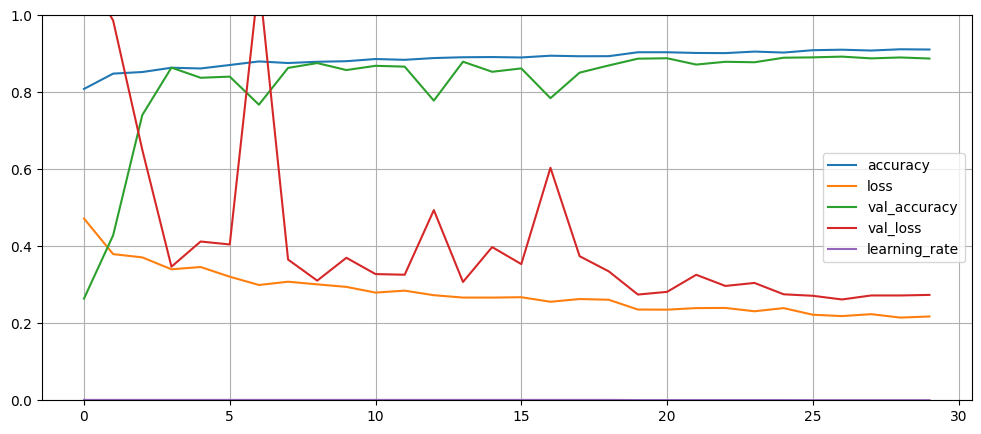

In [ ]:
pd.DataFrame(cnn.history).plot(figsize=(12,5))
plt.grid(True)
plt.gca().set_ylim(0,1)
plt.show()

In [ ]:
try:
    gpus = tf.config.experimental.list_physical_devices('GPU')
    if gpus:
        tf.config.experimental.set_memory_growth(gpus[0], True)
        print("GPU memory growth enabled.")
except Exception as e:
    print(f"Could not enable GPU memory growth: {e}")

def lightweight_conv_block(inputs, filters, dropout_rate=0.1):
    """Lightweight convolutional block - single conv + batch norm + dropout"""
    conv = Conv2D(filters, (3, 3), padding='same')(inputs)
    conv = BatchNormalization()(conv)
    conv = Activation('relu')(conv)
    conv = Dropout(dropout_rate)(conv)
    return conv

# Define the Model Architecture for clarity and robust loading
def build_lightweight_model(input_shape=(128, 128, 12), num_classes=3):
    input_layer = Input(shape=input_shape)

    # Encoder
    conv1 = lightweight_conv_block(input_layer, 32, dropout_rate=0.1)
    pool1 = MaxPooling2D((2, 2))(conv1)

    conv2 = lightweight_conv_block(pool1, 64, dropout_rate=0.1)
    pool2 = MaxPooling2D((2, 2))(conv2)

    conv3 = lightweight_conv_block(pool2, 128, dropout_rate=0.2)
    pool3 = MaxPooling2D((2, 2))(conv3)

    # Bottleneck
    conv4 = lightweight_conv_block(pool3, 256, dropout_rate=0.2)

    # Decoder
    up1 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv4)
    up1 = concatenate([up1, conv3])
    conv5 = lightweight_conv_block(up1, 128, dropout_rate=0.2)

    up2 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv5)
    up2 = concatenate([up2, conv2])
    conv6 = lightweight_conv_block(up2, 64, dropout_rate=0.1)

    up3 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(conv6)
    up3 = concatenate([up3, conv1])
    conv7 = lightweight_conv_block(up3, 32, dropout_rate=0.1)

    # Output layer
    output_layer = Conv2D(num_classes, (1, 1), activation='softmax')(conv7)

    model = Model(inputs=input_layer, outputs=output_layer)
    return model

# Define Model Paths
MODEL_LOAD_PATH = '/content/drive/MyDrive/Forest_AI_Data/reduced_data_atandard_model_without_focal_loss_91.keras'
# Define the new save path for the continued model
MODEL_SAVE_DIR = '/content/drive/MyDrive/Forest_AI_Data/'
MODEL_SAVE_NAME = 'reduced_data_standard_model_without_focal_loss_91_continuation.keras'
MODEL_SAVE_PATH = os.path.join(MODEL_SAVE_DIR, MODEL_SAVE_NAME)

# Load the Model
print(f"Loading model from: {MODEL_LOAD_PATH}")
try:
    loaded_model = tf.keras.models.load_model(
        MODEL_LOAD_PATH,
        custom_objects={'lightweight_conv_block': lightweight_conv_block}
    )
    print("Model loaded successfully.")
    # Print a summary to confirm it's the correct model
    loaded_model.summary()
except Exception as e:
    print(f"Error loading model: {e}")
    print("Please ensure the model path is correct and the `lightweight_conv_block` function is defined.")
    # Exit or handle the error appropriately if the model cannot be loaded
    exit() # Exit the script if loading fails

callbacks_continuation = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=MODEL_SAVE_PATH, # New path for saving the best model of this continuation
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

# Set Continuation Training Parameters ---
INITIAL_EPOCH = 30
ADDITIONAL_EPOCHS = 30
TOTAL_EPOCHS = INITIAL_EPOCH + ADDITIONAL_EPOCHS
BATCH_SIZE_CONTINUATION = 16 # higher batch size

tf.keras.backend.clear_session()
gc.collect()

history_continuation = loaded_model.fit(
    x=train_samples,
    y=train_labels,
    validation_split=0.15,
    batch_size=BATCH_SIZE_CONTINUATION,
    epochs=TOTAL_EPOCHS,
    initial_epoch=INITIAL_EPOCH, # Tell Keras to start counting epochs from 30
    shuffle=True,
    callbacks=callbacks_continuation,
    verbose=1
)

print(f"\n--- Continued training complete ---")
print(f"The best model from this continuation run has been saved to: {MODEL_SAVE_PATH}")

# --- 10. Clean up memory after training ---
gc.collect()

Loading model from: /content/drive/MyDrive/Forest_AI_Data/reduced_data_atandard_model_without_focal_loss_91.keras
Model loaded successfully.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      3,488 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128, 128,  │          0 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ dropout[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 64,    │          0 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ dropout_1[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32, 32,    │          0 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ dropout_2[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_2[

 Total params: 2,857,611 (10.90 MB)

 Trainable params: 952,067 (3.63 MB)

 Non-trainable params: 1,408 (5.50 KB)

 Optimizer params: 1,904,136 (7.26 MB)


--- Starting Model Continuation Training ---
Model will train from epoch 30 up to 60 (another 30 epochs).
Using batch size: 16
Best model from this run will be saved to: /content/drive/MyDrive/Forest_AI_Data/reduced_data_standard_model_without_focal_loss_91_continuation.keras
Epoch 31/60
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.9109 - loss: 0.2152
Epoch 31: val_loss improved from inf to 0.29764, saving model to /content/drive/MyDrive/Forest_AI_Data/reduced_data_standard_model_without_focal_loss_91_continuation.keras
62/62 ━━━━━━━━━━━━━━━━━━━━ 453s 7s/step - accuracy: 0.9110 - loss: 0.2151 - val_accuracy: 0.8777 - val_loss: 0.2976 - learning_rate: 2.5000e-04
Epoch 32/60
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.9132 - loss: 0.2097
Epoch 32: val_loss improved from 0.29764 to 0.27408, saving model to /content/drive/MyDrive/Forest_AI_Data/reduced_data_standard_model_without_focal_loss_91_continuation.keras
62/62 ━━━━━━━━━━━━━━━━━━━━ 432s 7s/step - accuracy: 0.9132 - l

359

##Predict and Evaluate

In [ ]:
test_samples_patches.shape

(288, 128, 128, 12)

In [ ]:
#patches, positions = extract_patches_for_inference(test_samples)
preds = model.predict(test_samples_patches)
pred_classes = np.argmax(preds, axis=-1)  # Shape: (N, 128, 128)


9/9 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step


In [ ]:
print("Patches type:", type(pred_classes))
print("Patches shape/length:", len(pred_classes) if hasattr(pred_classes, '__len__') else 'No length')
print("First patch shape:", pred_classes[0].shape if len(pred_classes) > 0 else 'Empty')

Patches type: <class 'numpy.ndarray'>
Patches shape/length: 288
First patch shape: (128, 128)


In [ ]:
# original image dimensions
# h, w = 1560, 3110
# patch_size = 128
# stride = 128

# Grid dimensions
num_rows = 12
num_cols = 24

# Reshape your prediction patches
patches_2d = pred_classes.reshape(num_rows, num_cols, 128, 128)

# Stitch together
result = patches_2d.transpose(0, 2, 1, 3).reshape(
    num_rows * 128,
    num_cols * 128
)

print(f"Stitched result shape: {result.shape}")
# Should be: (1536, 3072)

Stitched result shape: (1536, 3072)


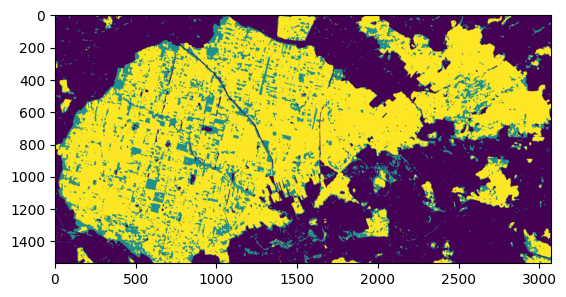

In [ ]:
plt.figure()
plt.imshow(result)

Count of 0: 1943853
Count of 1: 636795
Count of 2: 2137944


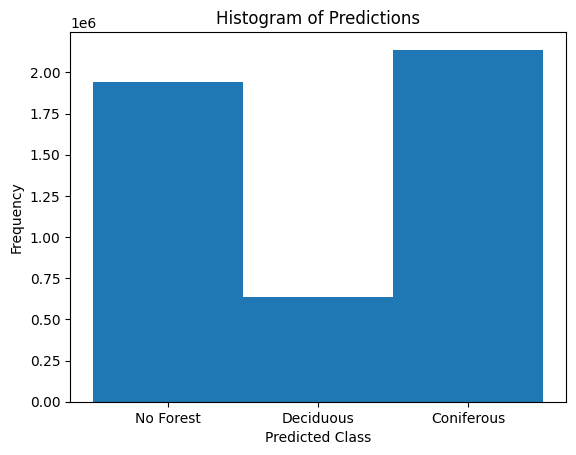

In [ ]:
from collections import Counter

# Ensure pred_classes is a numpy array and flatten it
result_flat = np.array(result).flatten()

# Count occurrences
counts = Counter(result_flat)

# Print the counts for 0, 1, and 2
print("Count of 0:", counts.get(0, 0))
print("Count of 1:", counts.get(1, 0))
print("Count of 2:", counts.get(2, 0))

plt.hist(result_flat, bins=[0, 1, 2, 3])
plt.title("Histogram of Predictions")
plt.xlabel("Predicted Class")
plt.ylabel("Frequency")
plt.xticks([0.5, 1.5, 2.5], ['No Forest', 'Deciduous', 'Coniferous'])  # Set x-axis ticks to bin centers
plt.show()

The extracted Patches cover 1536*3072 pixels --> 4718592 pixels total per band

In [ ]:
test_labels.shape

(1560, 3110, 1)

In [ ]:
test_labels = test_labels[0:1536,0:3072,:] # 1536*3072 pixels
test_labels.shape

(1536, 3072, 1)

In [ ]:
# confusion matrix needs 1D arrays
test_labels = test_labels.reshape(-1)
result_cm = result.reshape(-1)
print(test_labels.shape)
print(result_cm.shape)

(4718592,)
(4718592,)


In [ ]:
cm = confusion_matrix(y_true = test_labels, y_pred = result_cm)
cm

array([[1917933,   47168,   12041],
       [  24128,  543245,  151379],
       [   1792,   46382, 1974524]])

In [ ]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], '.2f'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

--- Confusion Matrix Breakdown ---
True Positives per Class: [1917933  543245 1974524]
Actual Count per Class: [1977142  718752 2022698]
------------------------------
Total Pixels: 4718592
Total Correctly Classified Pixels: 4435702
------------------------------
Overall Accuracy: 94.00%
------------------------------
Percentage of Correctly Classified Pixels per Class (Recall):
  Class 0: 97.01%
  Class 1: 75.58%
  Class 2: 97.62%
------------------------------

Percentage of Correctly Predicted Pixels that are Accurate (Precision):
  Class 0: 98.67%
  Class 1: 85.31%
  Class 2: 92.36%
------------------------------
Confusion matrix, without normalization
[[1917933   47168   12041]
 [  24128  543245  151379]
 [   1792   46382 1974524]]


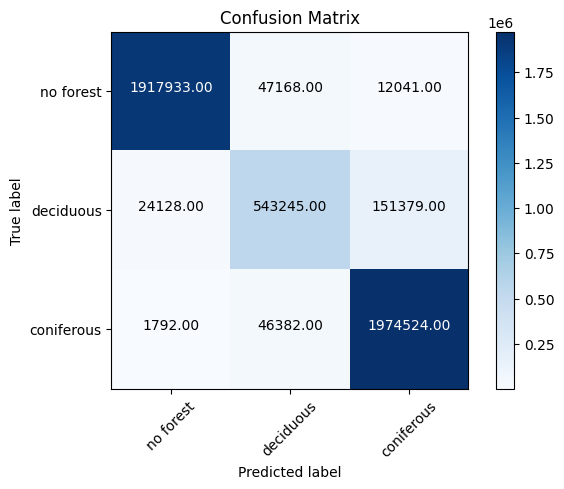

In [ ]:
cm_plot_labels = ['no forest','deciduous', 'coniferous']
import numpy as np

# Extract True Positives for each class (diagonal elements)
true_positives = np.diag(cm)

# Calculate Actual Class Counts (sum of each row)
actual_class_counts = np.sum(cm, axis=1)

# Calculate Total Pixels
total_pixels = np.sum(cm)

# Calculate Total Correctly Classified Pixels
total_correctly_classified = np.sum(true_positives)

# Calculate Overall Accuracy
overall_accuracy = (total_correctly_classified / total_pixels) * 100

print("--- Confusion Matrix Breakdown ---")
print("True Positives per Class:", true_positives)
print("Actual Count per Class:", actual_class_counts)
print("-" * 30)
print("Total Pixels:", total_pixels)
print("Total Correctly Classified Pixels:", total_correctly_classified)
print("-" * 30)
print(f"Overall Accuracy: {overall_accuracy:.2f}%")
print("-" * 30)
# Calculate percentage of correctly classified pixels per class (Recall)
percentage_correct_per_class = (true_positives / actual_class_counts) * 100

print("Percentage of Correctly Classified Pixels per Class (Recall):")
for i, percentage in enumerate(percentage_correct_per_class):
    print(f"  Class {i}: {percentage:.2f}%")
print("-" * 30)
# You can also compute Precision (True Positives / Predicted Positives) for completeness
predicted_class_counts = np.sum(cm, axis=0)
precision_per_class = (true_positives / predicted_class_counts) * 100

print("\nPercentage of Correctly Predicted Pixels that are Accurate (Precision):")
for i, percentage in enumerate(precision_per_class):
    print(f"  Class {i}: {percentage:.2f}%")
print("-" * 30)
plot_confusion_matrix(cm=cm, classes=cm_plot_labels, title='Confusion Matrix')

In [ ]:
# Define the path to save the model in your Google Drive
model_save_path = '/content/drive/MyDrive/Forest_AI_Data/forest_classification_model_1.keras'

# Save the entire model
try:
    model.save(model_save_path)
    print(f"Model saved successfully to: {model_save_path}")
except Exception as e:
    print(f"Error saving the model: {e}")

Model saved successfully to: /content/drive/MyDrive/Forest_AI_Data/forest_classification_model_1.keras
